# Evaluation

This notebook builds a **DQN (Deep Q-Network)** agent from any tabular dataset where you configure:
- **Action column** and optional explicit action space
- **State space** (explicit list, prefix-based, or automatic)
- **Objective columns/weights** (for example latency + action cost)

The environment is created from the dataset using nearest-neighbor transition sampling within each action bucket.

In [1]:
import numpy as np
import pandas as pd
from collections import defaultdict, deque
import random
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

np.random.seed(17)
random.seed(17)
torch.manual_seed(17)

In [2]:
# ---- Config ----
DATE = "260320"
TRAIN_DATA_PATH = f"data/{DATE}/services_real_dataset_bd.csv"
EVAL_DATA_PATH = f"data/{DATE}/services_real_dataset_ud.csv"
BD_PATH = TRAIN_DATA_PATH

# Agent Selection
USE_TABULAR_AGENT = True

# Optional explicit columns to load from each dataset.
# If None, all columns are loaded.
KEEP_COLUMNS = None

# State-space selection modes:
STATE_SPACE_COLS = [
    "service_frame_resizer_replicas",
    "service_object_detector_replicas",
    "service_frame_sampler_arrival_rate"
]
STATE_COL_PREFIX = None

# Action and objective schema.
# The agent will jointly decide actions for these columns.
ACTION_COLUMNS = [
    "service_frame_resizer_replicas", 
    "service_object_detector_replicas"
]
LATENCY_COLUMN = "service_object_detector_latency" # Using final stage latency as e2e

# Optional explicit action space. If None, inferred from data.
ACTION_SPACE = None

# Reward/objective weights (kept for compatibility with analysis cells).
OBJECTIVES = {
    "sla_latency_ms": 100.0,
    "violation_weight": 5.0,
    "violation_fixed_penalty": 150.0,
    "replica_weight": 5.0,
}

# Paper-style reward parameters (serverless-orchestration.pdf).
R_MAX = 100.0
W_LAT = 1.0 / 3.0
W_RES = 2.0 / 3.0
LAT_BELOW_REF_DECAY = 0.06
LAT_ABOVE_REF_DECAY = 10.0
LAT_SHAPE_GAIN = 1.0
INVALID_OR_SLO_PENALTY = -100.0

# Optional causal config
CAUSAL_GRAPH_LABELS = None
CAUSAL_GRAPH_ADJ = None
CAUSAL_GRAPH_TO_ENV_COL = None
CAUSAL_TARGET_LABEL = None
CAUSAL_PARENT_WEIGHT_THRESHOLD = 0.2

# Single split config on eval dataset.
UD_TRAIN_SPLIT_FRAC = 0.8
UD_SPLIT_SEED = 42

N_BINS = 6
# Multi-step episodes provide denser learning signal than 1-step bandit episodes.
MAX_STEPS_PER_EPISODE = 5

EPISODES = 6000
ALPHA = 0.001 if not USE_TABULAR_AGENT else 0.1
GAMMA = 0.90
EPSILON_START = 0.2 if not USE_TABULAR_AGENT else 1.0
EPSILON_END = 0.0 if not USE_TABULAR_AGENT else 0.01
EPSILON_DECAY = 1.0 if not USE_TABULAR_AGENT else 0.995

# DQN training knobs (paper-style offline training flow).
DQN_REPLAY_BUFFER_SIZE = 50000
DQN_BATCH_SIZE = 64
DQN_REPLAY_WARMUP_EPOCHS = 100
DQN_TARGET_UPDATE_EPOCHS = 5
DQN_UPDATES_PER_STEP = 1
DQN_HIDDEN_DIM_1 = 64
DQN_HIDDEN_DIM_2 = 64
DQN_EVAL_INTERVAL_EPOCHS = 50
DQN_EVAL_EPISODES = 3

# Backward-compatible aliases used by downstream cells.
SLA_LATENCY_MS = float(OBJECTIVES["sla_latency_ms"])
VIOLATION_WEIGHT = float(OBJECTIVES["violation_weight"])
VIOLATION_FIXED_PENALTY = float(OBJECTIVES["violation_fixed_penalty"])
REPLICA_WEIGHT = float(OBJECTIVES["replica_weight"])

## Load dataset

In [3]:
# ---- Dataset loading helpers ----
state_col_prefix = STATE_COL_PREFIX
od_prefix = state_col_prefix  # Backward-compatible alias used in later cells.
action_cols = ACTION_COLUMNS
latency_col = LATENCY_COLUMN


def _validate_required_columns(df_local, required_cols, path_label):
    missing = [c for c in required_cols if c not in df_local.columns]
    if missing:
        raise ValueError(f"Missing required columns in {path_label}: {missing}")


def _resolve_state_columns(df_local, state_cols_override=None):
    if state_cols_override is not None:
        state_cols_local = list(dict.fromkeys(state_cols_override))
    elif state_col_prefix is not None:
        state_cols_local = [c for c in df_local.columns if c.startswith(state_col_prefix)]
    else:
        state_cols_local = [c for c in df_local.columns if c not in set(action_cols) | {latency_col}]

    if not state_cols_local:
        raise ValueError(
            "State space is empty. Set STATE_SPACE_COLS, STATE_COL_PREFIX, or provide non-action/objective columns."
        )

    # Ensure action and objective columns are always available in state representation.
    for ac in action_cols:
        if ac not in state_cols_local:
            state_cols_local.append(ac)
    if latency_col not in state_cols_local:
        state_cols_local.append(latency_col)

    return state_cols_local


def _normalize_actions(df_actions, explicit_action_space=None):
    # If dealing with multiple columns, actions are tuples of values
    if explicit_action_space is None:
        return sorted(list(set(tuple(x) for x in df_actions.to_numpy())))
    return sorted(list(set(tuple(int(v) for v in a) for a in explicit_action_space)))


def load_od_dataset(path, keep_columns=None, state_cols_override=None, explicit_action_space=None):
    data = pd.read_csv(path).dropna().reset_index(drop=True)

    if keep_columns is not None:
        keep = list(dict.fromkeys(list(keep_columns) + action_cols + [latency_col]))
        _validate_required_columns(data, keep, path)
        data = data[keep].copy()

    _validate_required_columns(data, action_cols + [latency_col], path)
    for ac in action_cols:
        data[ac] = data[ac].round().astype(int)

    state_cols_local = _resolve_state_columns(data, state_cols_override=state_cols_override)
    actions_local = _normalize_actions(data[action_cols], explicit_action_space=explicit_action_space)

    return {
        "path": path,
        "df": data,
        "state_cols": state_cols_local,
        "actions": actions_local,
    }


def dataset_info_from_df(df, path_label, keep_columns=None, state_cols_override=None, explicit_action_space=None):
    data = df.copy().dropna().reset_index(drop=True)

    if keep_columns is not None:
        keep = list(dict.fromkeys(list(keep_columns) + action_cols + [latency_col]))
        _validate_required_columns(data, keep, path_label)
        data = data[keep].copy()

    _validate_required_columns(data, action_cols + [latency_col], path_label)
    for ac in action_cols:
        data[ac] = data[ac].round().astype(int)

    state_cols_local = _resolve_state_columns(data, state_cols_override=state_cols_override)
    actions_local = _normalize_actions(data[action_cols], explicit_action_space=explicit_action_space)

    return {
        "path": path_label,
        "df": data,
        "state_cols": state_cols_local,
        "actions": actions_local,
    }


def set_action_space(dataset_info, actions_space):
    dataset_info["actions"] = sorted(list(set(tuple(int(v) for v in a) for a in actions_space)))
    dataset_info["action_to_idx"] = {a: i for i, a in enumerate(dataset_info["actions"])}
    dataset_info["idx_to_action"] = {i: a for a, i in dataset_info["action_to_idx"].items()}


train_data = load_od_dataset(
    TRAIN_DATA_PATH,
    keep_columns=KEEP_COLUMNS,
    state_cols_override=STATE_SPACE_COLS,
    explicit_action_space=ACTION_SPACE,
)
ud_full_data = load_od_dataset(
    EVAL_DATA_PATH,
    keep_columns=KEEP_COLUMNS,
    state_cols_override=STATE_SPACE_COLS,
    explicit_action_space=ACTION_SPACE,
)

# Create a single consistent train/test split of the unbiased dataset
rng = np.random.default_rng(UD_SPLIT_SEED)
n_samples = len(ud_full_data["df"])
perm = rng.permutation(n_samples)
split_idx = int(n_samples * UD_TRAIN_SPLIT_FRAC)
train_idx = perm[:split_idx]
test_idx = perm[split_idx:]

ud_train_data = dataset_info_from_df(
    ud_full_data["df"].iloc[train_idx],
    "eval_train_data",
    keep_columns=KEEP_COLUMNS,
    state_cols_override=STATE_SPACE_COLS,
    explicit_action_space=ACTION_SPACE,
)
ud_test_data = dataset_info_from_df(
    ud_full_data["df"].iloc[test_idx],
    "eval_test_data",
    keep_columns=KEEP_COLUMNS,
    state_cols_override=STATE_SPACE_COLS,
    explicit_action_space=ACTION_SPACE,
)

GLOBAL_ACTIONS = sorted(set(train_data["actions"]) | set(ud_full_data["actions"]))
set_action_space(train_data, GLOBAL_ACTIONS)
set_action_space(ud_train_data, GLOBAL_ACTIONS)
set_action_space(ud_test_data, GLOBAL_ACTIONS)

eval_data = ud_test_data

print(f"Global actions: {GLOBAL_ACTIONS}")
print(f"State space size: {len(train_data['state_cols'])}")
print(f"Action columns: {action_cols} | Objective latency column: {latency_col}")
print(f"Train rows: {len(train_data['df'])}")
print(f"Eval total rows: {len(ud_full_data['df'])}")
print(f"Eval-train rows: {len(ud_train_data['df'])} | eval-test rows: {len(ud_test_data['df'])}")

Global actions: [(1, 1), (1, 2), (1, 3), (2, 1), (2, 2), (2, 3), (3, 1), (3, 2), (3, 3)]
State space size: 4
Action columns: ['service_frame_resizer_replicas', 'service_object_detector_replicas'] | Objective latency column: service_object_detector_latency
Train rows: 458
Eval total rows: 1328
Eval-train rows: 1062 | eval-test rows: 266


In [4]:
# ---- Feature helpers (per dataset) ----
def build_dataset_artifacts(dataset_info, n_bins=N_BINS):
    df_local = dataset_info["df"]
    state_cols_local = dataset_info["state_cols"]

    state_matrix_local = df_local[state_cols_local].to_numpy(dtype=float)
    mu_local = state_matrix_local.mean(axis=0)
    sigma_local = state_matrix_local.std(axis=0) + 1e-8
    state_matrix_norm_local = (state_matrix_local - mu_local) / sigma_local

    bin_edges_local = {}
    for c in state_cols_local:
        q = np.linspace(0, 1, n_bins + 1)
        e = np.quantile(df_local[c].to_numpy(dtype=float), q)
        e = np.unique(e)
        if len(e) < 3:
            v = df_local[c].to_numpy(dtype=float)
            e = np.array([v.min() - 1e-6, v.max() + 1e-6])
        bin_edges_local[c] = e

    def discretize_row_local(row_values):
        s = []
        for i, c in enumerate(state_cols_local):
            e = bin_edges_local[c]
            b = np.digitize(row_values[i], e[1:-1], right=False)
            s.append(int(b))
        return tuple(s)

    return {
        "state_matrix": state_matrix_local,
        "state_matrix_norm": state_matrix_norm_local,
        "mu": mu_local,
        "sigma": sigma_local,
        "bin_edges": bin_edges_local,
        "discretize_row": discretize_row_local,
    }


train_artifacts = build_dataset_artifacts(train_data, n_bins=N_BINS)
ud_train_artifacts = build_dataset_artifacts(ud_train_data, n_bins=N_BINS)
ud_test_artifacts = build_dataset_artifacts(ud_test_data, n_bins=N_BINS)
eval_artifacts = ud_test_artifacts

## Causal Discovery

In [5]:
# ---- Optional: learn causal graph using CausalDiscovery(notears) ----
USE_NOTEARS_CAUSAL_GRAPH = True
NOTEARS_MAX_ITER = 100
NOTEARS_WEIGHT_THRESHOLD = 5.0

# List of allowed (source, target) tuples if you want to fix the structure and only calculate weights.
NOTEARS_FIXED_EDGES = [
    ('service_frame_sampler_arrival_rate', 'service_frame_resizer_arrival_rate'),
    ('service_frame_resizer_arrival_rate', 'service_object_detector_arrival_rate'),
    ('service_frame_resizer_replicas', 'service_object_detector_arrival_rate'),
    ('service_object_detector_replicas', 'e2e_latency'),
    ('service_object_detector_arrival_rate', 'e2e_latency'),
]
NOTEARS_FIXED_EDGES = None

# By default use the same columns used for environment state + latency.
CAUSAL_DISCOVERY_COLS = [
    'service_frame_sampler_arrival_rate',
    'service_frame_resizer_arrival_rate',
    'service_object_detector_arrival_rate',
    'service_frame_resizer_replicas',
    'service_object_detector_replicas',
    'e2e_latency'
]

if NOTEARS_FIXED_EDGES is not None:
    for u, v in NOTEARS_FIXED_EDGES:
        if u not in CAUSAL_DISCOVERY_COLS:
            CAUSAL_DISCOVERY_COLS.append(u)
        if v not in CAUSAL_DISCOVERY_COLS:
            CAUSAL_DISCOVERY_COLS.append(v)

from causality.causal_discovery import CausalDiscovery

# We will discover graphs for both BD (train_data) and UD (ud_train_data)
bd_causal_graph = {"labels": None, "adj": None, "mapping": None, "target": None, "error": None}
ud_causal_graph = {"labels": None, "adj": None, "mapping": None, "target": None, "error": None}

if USE_NOTEARS_CAUSAL_GRAPH:
    discovery_cols = CAUSAL_DISCOVERY_COLS if CAUSAL_DISCOVERY_COLS is not None else train_data["state_cols"]
    discovery_cols = list(dict.fromkeys(discovery_cols))
    
    # helper for discovering graph
    def discover_graph_for_df(df_source, name):
        actual_cols = [c for c in discovery_cols if c in df_source.columns]
        df_target = df_source[actual_cols].copy()
        try:
            cd = CausalDiscovery(method="notears")
            cd.fit(
                df_target,
                notears_w_threshold=NOTEARS_WEIGHT_THRESHOLD,
                notears_max_iter=NOTEARS_MAX_ITER,
                fixed_edges=NOTEARS_FIXED_EDGES,
            )
            labels = list(cd.labels_)
            adj = np.asarray(cd.adjacency_matrix_, dtype=float)
            mapping = {c: c for c in labels}
            target = latency_col if latency_col in labels else None
            print(f"[{name}] NOTEARS completed.")
            return {"labels": labels, "adj": adj, "mapping": mapping, "target": target, "error": None}
        except Exception as exc:
            print(f"[{name}] NOTEARS failed: {exc}")
            return {"labels": None, "adj": None, "mapping": None, "target": None, "error": str(exc)}

    print("Running Causal Discovery on BD (train_data)...")
    bd_causal_graph = discover_graph_for_df(train_data["df"], "BD")
    
    print("Running Causal Discovery on UD (ud_train_data)...")
    ud_causal_graph = discover_graph_for_df(ud_train_data["df"], "UD")

    # Set up globals for agent based on BD
    if bd_causal_graph["error"] is None:
        CAUSAL_GRAPH_LABELS = bd_causal_graph["labels"]
        CAUSAL_GRAPH_ADJ = bd_causal_graph["adj"]
        CAUSAL_GRAPH_TO_ENV_COL = bd_causal_graph["mapping"]
        CAUSAL_TARGET_LABEL = bd_causal_graph["target"]

        tgt_idx = CAUSAL_GRAPH_LABELS.index(CAUSAL_TARGET_LABEL) if CAUSAL_TARGET_LABEL in CAUSAL_GRAPH_LABELS else None
        if tgt_idx is not None:
            active_parents = [
                CAUSAL_GRAPH_LABELS[j]
                for j in range(len(CAUSAL_GRAPH_LABELS))
                if abs(CAUSAL_GRAPH_ADJ[tgt_idx, j]) > CAUSAL_PARENT_WEIGHT_THRESHOLD
            ]
        else:
            active_parents = []

        print(f"\nBD Target label: {CAUSAL_TARGET_LABEL}")
        print(f"BD Parents above threshold ({CAUSAL_PARENT_WEIGHT_THRESHOLD}): {active_parents}")
    else:
        CAUSAL_GRAPH_LABELS = None
        CAUSAL_GRAPH_ADJ = None
        CAUSAL_GRAPH_TO_ENV_COL = None
        CAUSAL_TARGET_LABEL = None
        print("Causal discovery for BD failed; agent will use fallback state.")
else:
    print("USE_NOTEARS_CAUSAL_GRAPH=False; causal agent will use configured CAUSAL_GRAPH_* or fallback.")

Running Causal Discovery on BD (train_data)...


/Users/gtzanettis/Documents/Projects/causality/venv/lib/python3.9/site-packages/causalnex/structure/notears.py:391: RuntimeWarning: overflow encountered in double_scalars
  return loss + 0.5 * rho * h * h + alpha * h
/Users/gtzanettis/Documents/Projects/causality/venv/lib/python3.9/site-packages/causalnex/structure/notears.py:407: RuntimeWarning: overflow encountered in multiply
  obj_grad = loss_grad + (rho * (np.trace(E) - d) + alpha) * E.T * W * 2
/Users/gtzanettis/Documents/Projects/causality/venv/lib/python3.9/site-packages/causalnex/structure/notears.py:407: RuntimeWarning: invalid value encountered in multiply
  obj_grad = loss_grad + (rho * (np.trace(E) - d) + alpha) * E.T * W * 2
/Users/gtzanettis/Documents/Projects/causality/venv/lib/python3.9/site-packages/causalnex/structure/notears.py:436: UserWarning: Failed to converge. Consider increasing max_iter.
  warnings.warn("Failed to converge. Consider increasing max_iter.")


[BD] NOTEARS completed.
Running Causal Discovery on UD (ud_train_data)...
[UD] NOTEARS completed.

BD Target label: None
BD Parents above threshold (0.2): []


/Users/gtzanettis/Documents/Projects/causality/venv/lib/python3.9/site-packages/causalnex/structure/notears.py:391: RuntimeWarning: overflow encountered in double_scalars
  return loss + 0.5 * rho * h * h + alpha * h
/Users/gtzanettis/Documents/Projects/causality/venv/lib/python3.9/site-packages/causalnex/structure/notears.py:407: RuntimeWarning: overflow encountered in multiply
  obj_grad = loss_grad + (rho * (np.trace(E) - d) + alpha) * E.T * W * 2
/Users/gtzanettis/Documents/Projects/causality/venv/lib/python3.9/site-packages/causalnex/structure/notears.py:407: RuntimeWarning: invalid value encountered in multiply
  obj_grad = loss_grad + (rho * (np.trace(E) - d) + alpha) * E.T * W * 2
/Users/gtzanettis/Documents/Projects/causality/venv/lib/python3.9/site-packages/causalnex/structure/notears.py:407: RuntimeWarning: overflow encountered in double_scalars
  obj_grad = loss_grad + (rho * (np.trace(E) - d) + alpha) * E.T * W * 2
/Users/gtzanettis/Documents/Projects/causality/venv/lib/py

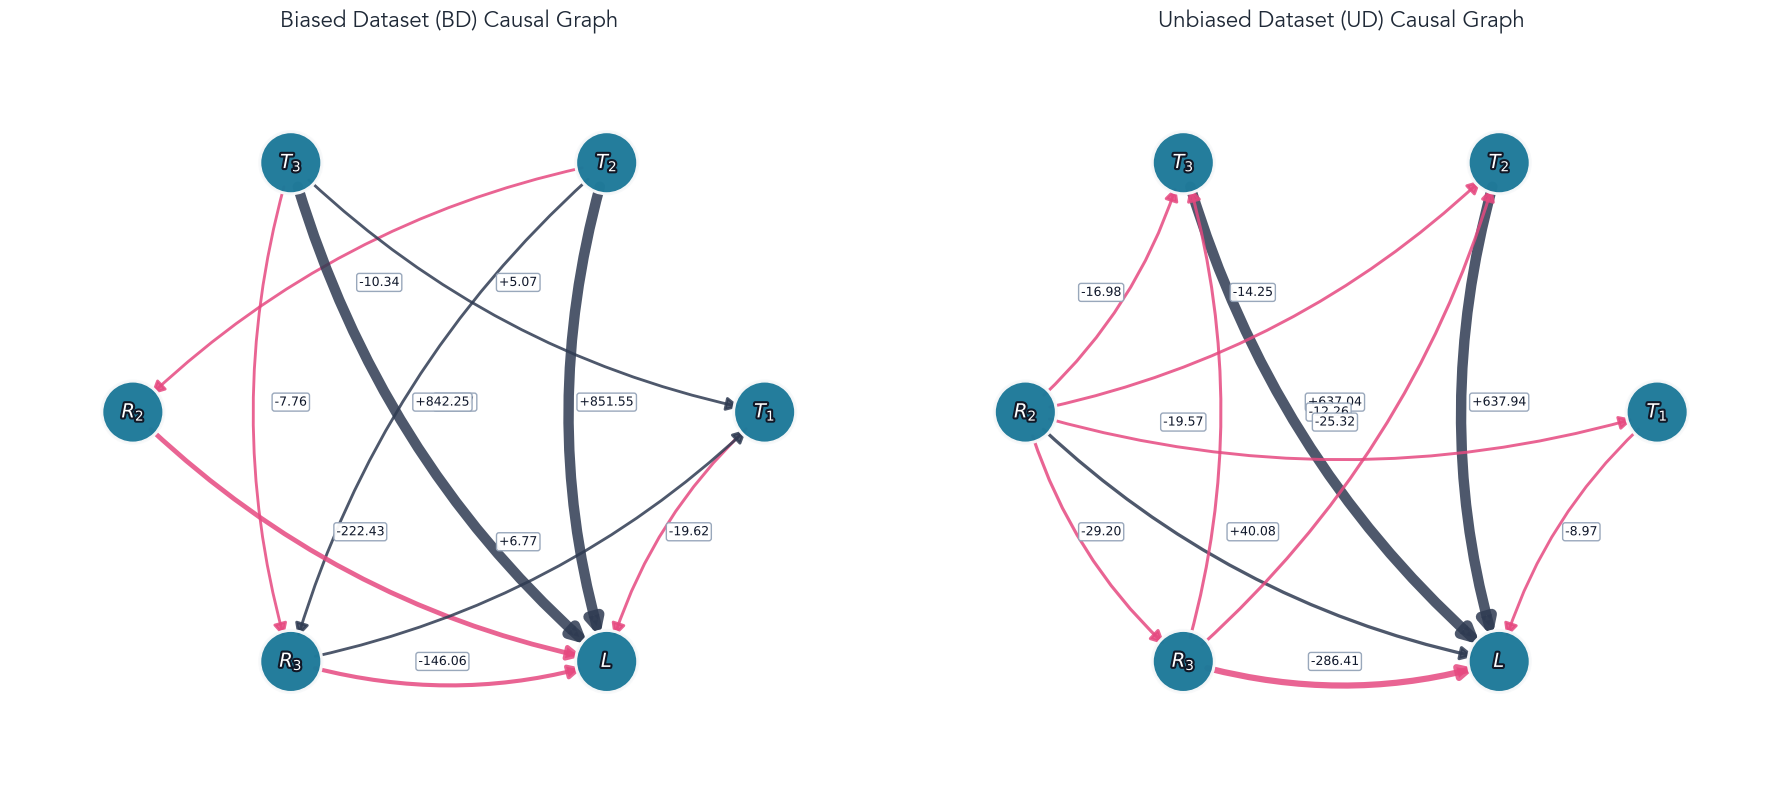

In [6]:
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import numpy as np

def draw_single_causal_graph(ax, labels, adj_matrix, target_label, title):
    if adj_matrix is None or labels is None:
        ax.text(0.5, 0.5, "Graph not available", ha='center', va='center', fontsize=14)
        ax.set_title(title)
        ax.axis("off")
        return

    G = nx.DiGraph()
    for label in labels:
        G.add_node(label)

    # Build strongly directed edges
    edge_candidates = []
    if NOTEARS_FIXED_EDGES is not None:
        for source, target in NOTEARS_FIXED_EDGES:
            if source in labels and target in labels:
                j = labels.index(source)
                i = labels.index(target)
                weight = float(adj_matrix[i, j])
                edge_candidates.append((source, target, weight))
    else:
        for i in range(len(labels)):
            for j in range(len(labels)):
                weight = float(adj_matrix[i, j])
                if i == j or abs(weight) <= 1e-6:
                    continue
                source = labels[j]
                target = labels[i]
                edge_candidates.append((source, target, weight))

    strongest_by_pair = {}
    for source, target, weight in edge_candidates:
        if NOTEARS_FIXED_EDGES is not None:
            strongest_by_pair[(source, target)] = (source, target, weight)
        else:
            pair_key = tuple(sorted((source, target)))
            prev = strongest_by_pair.get(pair_key)
            if prev is None or abs(weight) > abs(prev[2]):
                strongest_by_pair[pair_key] = (source, target, weight)

    for source, target, weight in strongest_by_pair.values():
        G.add_edge(source, target, weight=weight)

    n_nodes = max(1, len(G.nodes()))

    if n_nodes <= 8:
        pos = nx.circular_layout(G, scale=0.9)
    else:
        pos = nx.spring_layout(G, k=0.55 / np.sqrt(n_nodes), iterations=400, seed=42)

    node_colors = ["#ef5350" if node == target_label else "#1f7a9a" for node in G.nodes()]

    nx.draw_networkx_nodes(
        G, pos,
        node_color=node_colors,
        node_size=2000,
        linewidths=2.2,
        edgecolors="#f8f9fa",
        ax=ax,
        alpha=0.98,
    )

    edges = list(G.edges())
    weights = [abs(G[u][v]["weight"]) for u, v in edges]
    max_weight = max(weights) if weights else 1.0
    edge_widths = [2.0 + 5.5 * (w / max_weight) for w in weights]
    edge_colors = ["#2f3b52" if G[u][v]["weight"] >= 0 else "#e64980" for u, v in edges]

    nx.draw_networkx_edges(
        G, pos,
        width=edge_widths,
        edge_color=edge_colors,
        ax=ax, alpha=0.85,
        arrows=True, arrowsize=20, arrowstyle="-|>",
        connectionstyle="arc3,rad=0.15",
        min_source_margin=18, min_target_margin=18,
    )

    def format_node_label(node):
        if node == "service_frame_sampler_arrival_rate": return r"$T_{1}$"
        if node == "service_frame_resizer_arrival_rate": return r"$T_{2}$"
        if node == "service_object_detector_arrival_rate": return r"$T_{3}$"
        if node == "service_frame_resizer_replicas": return r"$R_{2}$"
        if node == "service_object_detector_replicas": return r"$R_{3}$"
        if node == "e2e_latency" or node == "service_object_detector_latency": return r"$L$"
        return node.replace("service_object_detector_", "").replace("_", " ")

    label_map = {node: format_node_label(node) for node in G.nodes()}
    
    node_text = nx.draw_networkx_labels(
        G, pos,
        labels=label_map,
        font_size=14, font_weight="bold", font_color="#ffffff",
        ax=ax,
    )
    for txt in node_text.values():
        txt.set_path_effects([pe.withStroke(linewidth=3.0, foreground="#111827")])

    edge_labels = {(u, v): f"{G[u][v]['weight']:+.2f}" for u, v in G.edges()}
    edge_text = nx.draw_networkx_edge_labels(
        G, pos,
        edge_labels=edge_labels,
        font_size=9, rotate=False, label_pos=0.52, font_color="#0f172a",
        bbox={"boxstyle": "round,pad=0.2", "fc": "#ffffff", "ec": "#94a3b8", "alpha": 0.95},
        ax=ax,
    )
    for txt in edge_text.values():
        txt.set_path_effects([pe.withStroke(linewidth=1.6, foreground="#ffffff")])

    ax.set_title(title, fontsize=16, fontweight="semibold", color="#1f2937", pad=12)
    ax.set_xlim(-1.25, 1.25)
    ax.set_ylim(-1.15, 1.15)
    ax.set_facecolor("#f6f8fb")
    ax.axis("off")


if USE_NOTEARS_CAUSAL_GRAPH:
    plt.rcParams["font.family"] = ["Avenir", "Helvetica Neue", "DejaVu Sans"]
    fig, axes = plt.subplots(1, 2, figsize=(18, 8))

    draw_single_causal_graph(
        axes[0],
        bd_causal_graph["labels"],
        bd_causal_graph["adj"],
        bd_causal_graph["target"],
        "Biased Dataset (BD) Causal Graph"
    )
    
    draw_single_causal_graph(
        axes[1],
        ud_causal_graph["labels"],
        ud_causal_graph["adj"],
        ud_causal_graph["target"],
        "Unbiased Dataset (UD) Causal Graph"
    )

    plt.tight_layout()
    plt.show()
else:
    print("Graph plotting skipped (USE_NOTEARS_CAUSAL_GRAPH=False)")

## Environment

In [7]:
# ---- Dataset-driven environment ----

import importlib
import envs.dataset_env
importlib.reload(envs.dataset_env)
from envs.dataset_env import DatasetEnv

def make_env(dataset_info, artifacts, sla_latency_ms=SLA_LATENCY_MS):
    return DatasetEnv(
        dataset_info=dataset_info,
        artifacts=artifacts,
        sla_latency_ms=sla_latency_ms,
        violation_weight=VIOLATION_WEIGHT,
        violation_fixed_penalty=VIOLATION_FIXED_PENALTY,
        replica_weight=REPLICA_WEIGHT,
        max_steps=MAX_STEPS_PER_EPISODE,
        action_cols=action_cols,
        latency_col=latency_col,
        r_max=R_MAX,
        w_lat=W_LAT,
        w_res=W_RES,
        lat_below_ref_decay=LAT_BELOW_REF_DECAY,
        lat_above_ref_decay=LAT_ABOVE_REF_DECAY,
        lat_shape_gain=LAT_SHAPE_GAIN,
        invalid_or_slo_penalty=INVALID_OR_SLO_PENALTY,
        is_discrete=USE_TABULAR_AGENT,
    )

## Agents

In [8]:
# ---- DQN agents: train 3 agents (train-set, eval-train-set, causal-train-set) ----
import importlib
import agents.agents
importlib.reload(agents.agents)

from agents.agents import (
    DQNNetwork,
    ReplayBuffer,
    QLearningAgent,
    CausalQLearningAgent,
    QTablePolicyAdapter,
    train_q_learning,
    TabularQLearningAgent,
    CausalTabularQLearningAgent
)

AgentClass = TabularQLearningAgent if USE_TABULAR_AGENT else QLearningAgent
CausalAgentClass = CausalTabularQLearningAgent if USE_TABULAR_AGENT else CausalQLearningAgent

def get_agent_kwargs(is_causal=False):
    kwargs = {}
    if USE_TABULAR_AGENT:
        kwargs.update({
            "alpha": ALPHA,
            "gamma": GAMMA,
            "epsilon_start": EPSILON_START,
            "epsilon_end": EPSILON_END,
            "epsilon_decay": EPSILON_DECAY
        })
    if is_causal:
        kwargs.update({
            "causal_graph_adj": CAUSAL_GRAPH_ADJ,
            "causal_graph_labels": CAUSAL_GRAPH_LABELS,
            "graph_to_env_col": CAUSAL_GRAPH_TO_ENV_COL,
            "target_label": CAUSAL_TARGET_LABEL,
            "parent_weight_threshold": CAUSAL_PARENT_WEIGHT_THRESHOLD,
            "action_cols": action_cols,
            "latency_col": latency_col
        })
    return kwargs

# --- Training the agents ---
biased_train_env = make_env(train_data, train_artifacts)
unbiased_train_env = make_env(ud_train_data, ud_train_artifacts)
unbiased_eval_env = make_env(ud_test_data, ud_test_artifacts)
causal_train_env = make_env(train_data, train_artifacts)

biased_agent = AgentClass(biased_train_env, **get_agent_kwargs())
_, episode_returns_biased, _, _ = biased_agent.train(episodes=EPISODES)

unbiased_agent = AgentClass(unbiased_train_env, **get_agent_kwargs())
_, episode_returns_unbiased, _, _ = unbiased_agent.train(episodes=EPISODES)

causal_biased_agent = CausalAgentClass(
    causal_train_env,
    **get_agent_kwargs(is_causal=True)
)
_, episode_returns_causal_biased, _, _ = causal_biased_agent.train(episodes=EPISODES)

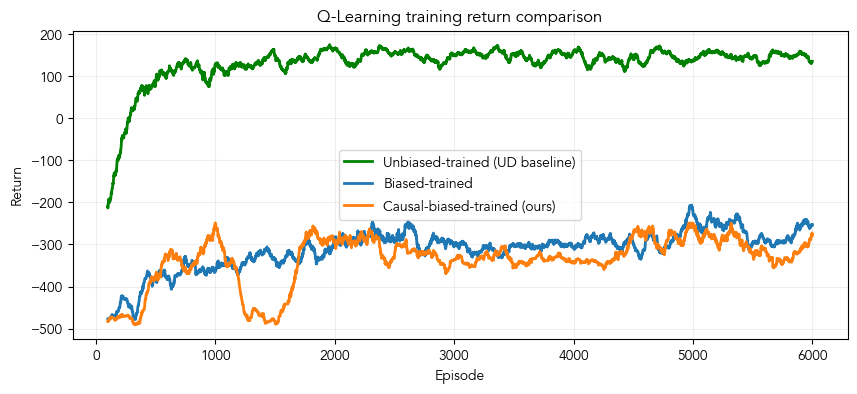

In [9]:
# ---- Training curves (biased-trained vs unbiased-trained vs causal-biased) ----
window = 100

ret_b = np.array(episode_returns_biased)
ma_b = np.convolve(ret_b, np.ones(window)/window, mode="valid")

ret_u = np.array(episode_returns_unbiased)
ma_u = np.convolve(ret_u, np.ones(window)/window, mode="valid")

ret_c = np.array(episode_returns_causal_biased)
ma_c = np.convolve(ret_c, np.ones(window)/window, mode="valid")

plt.figure(figsize=(10, 4))
plt.plot(np.arange(window-1, len(ret_u)), ma_u, linewidth=2.0, label="Unbiased-trained (UD baseline)", color="green")
plt.plot(np.arange(window-1, len(ret_b)), ma_b, linewidth=2.0, label="Biased-trained", color="#1f77b4")
plt.plot(np.arange(window-1, len(ret_c)), ma_c, linewidth=2.0, label="Causal-biased-trained (ours)", color="#ff7f0e")


plt.title("Q-Learning training return comparison")
plt.xlabel("Episode")
plt.ylabel("Return")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [10]:
# ---- Evaluate all agents on unbiased env ----
def evaluate_policy(env, policy, episodes=200):
    if hasattr(policy, "greedy_action"):
        policy_obj = policy
    else:
        policy_obj = QTablePolicyAdapter(env, policy)

    total_reward = 0.0
    latencies = []
    # `replicas` now stores tuples of actions
    replicas = []
    violations = 0
    steps = 0

    for _ in range(episodes):
        s = env.reset()
        done = False
        while not done:
            a_idx = policy_obj.greedy_action(s)
            s, r, done, info = env.step(a_idx)
            total_reward += r
            latencies.append(info["latency"])
            replicas.append(info["replicas"]) # info["replicas"] is a tuple
            violations += int(info["violation"])
            steps += 1

    # We track average total replicas per step, plus string representation of the avg per component
    avg_tuple = tuple(np.mean([r[i] for r in replicas]) for i in range(len(env.action_cols)))
    
    return {
        "avg_reward": total_reward / steps,
        "avg_latency": float(np.mean(latencies)),
        "p95_latency": float(np.percentile(latencies, 95)),
        # Average of the sum of replicas across all components
        "avg_replicas": float(np.mean([sum(r) for r in replicas])),
        "avg_replicas_tuple": str(tuple(round(x, 2) for x in avg_tuple)),
        "violation_rate": violations / steps,
        "total_steps": steps,
    }


biased_agent_on_unbiased_eval = evaluate_policy(unbiased_eval_env, biased_agent, episodes=300)
unbiased_agent_on_unbiased_eval = evaluate_policy(unbiased_eval_env, unbiased_agent, episodes=300)
causal_biased_agent_on_unbiased_eval = evaluate_policy(unbiased_eval_env, causal_biased_agent, episodes=300)

comparison_df = pd.DataFrame([
    {"agent": "biased-trained", **biased_agent_on_unbiased_eval},
    {"agent": "unbiased-trained", **unbiased_agent_on_unbiased_eval},
    {"agent": "causal-biased-trained", **causal_biased_agent_on_unbiased_eval},
])

comparison_df

,agent,avg_reward,avg_latency,p95_latency,avg_replicas,avg_replicas_tuple,violation_rate,total_steps
0,biased-trained,-85.164591,509.404746,843.717441,3.378667,"(1.77, 1.61)",0.903333,1500
1,unbiased-trained,-10.686158,104.464302,142.579804,4.967333,"(2.09, 2.87)",0.367333,1500
2,causal-biased-trained,-74.272652,491.920465,843.717441,2.919333,"(1.07, 1.85)",0.835333,1500


In [11]:
# ---- Feasibility diagnostic: best-achievable violation for a dataset ----
def knn_lower_bound_violation(df, state_cols, sla_values=(80, 100, 120, 150, 200), k=15):
    transition_cols = [c for c in state_cols if c not in set(action_cols) | {latency_col}]

    data = df.copy()
    for ac in action_cols:
        data[ac] = data[ac].round().astype(int)
    
    actions_local = sorted(list(set(tuple(x) for x in data[action_cols].to_numpy())))

    X = data[transition_cols].to_numpy(dtype=float)
    mu = X.mean(axis=0)
    sigma = X.std(axis=0) + 1e-8
    Xn = (X - mu) / sigma

    idx_by_action = {}
    for a in actions_local:
         mask = np.ones(len(data), dtype=bool)
         for i, col in enumerate(action_cols):
             mask &= (data[col].values == a[i])
         idx_by_action[a] = np.where(mask)[0]

    out = []
    for sla in sla_values:
        viol = 0
        for i in range(len(data)):
            xi = Xn[i]
            best_estimated_latency = np.inf
            for a in actions_local:
                ids = idx_by_action[a]
                if len(ids) == 0:
                    continue
                d2 = ((Xn[ids] - xi) ** 2).sum(axis=1)
                top = ids[np.argsort(d2)[:k]]
                est_latency = float(np.mean(data.iloc[top][latency_col].values))
                best_estimated_latency = min(best_estimated_latency, est_latency)
            viol += int(best_estimated_latency > sla)
        out.append({"sla": float(sla), "knn_lower_bound_violation": viol / len(data)})

    return pd.DataFrame(out)


print("Train-set lower bound")
train_lower_bound_df = knn_lower_bound_violation(
    train_data["df"],
    state_cols=train_data["state_cols"],
    sla_values=(80, 100, 120, 150, 200, 250),
    k=15,
 )
print(train_lower_bound_df)

print("\nEval-set lower bound")
eval_lower_bound_df = knn_lower_bound_violation(
    eval_data["df"],
    state_cols=eval_data["state_cols"],
    sla_values=(80, 100, 120, 150, 200, 250),
    k=15,
 )
eval_lower_bound_df

Train-set lower bound
     sla  knn_lower_bound_violation
0   80.0                   1.000000
1  100.0                   1.000000
2  120.0                   0.973799
3  150.0                   0.893013
4  200.0                   0.000000
5  250.0                   0.000000

Eval-set lower bound


,sla,knn_lower_bound_violation
0,80.0,0.0
1,100.0,0.0
2,120.0,0.0
3,150.0,0.0
4,200.0,0.0
5,250.0,0.0


In [12]:
# ---- Auto-relax SLA until eval violation rate < 5% ----
def train_and_eval_for_sla(train_dataset, train_ds_artifacts, eval_dataset, eval_ds_artifacts, sla_value, train_episodes=1500, eval_episodes=200):
    local_train_env = make_env(train_dataset, train_ds_artifacts, sla_latency_ms=float(sla_value))
    local_eval_env = make_env(eval_dataset, eval_ds_artifacts, sla_latency_ms=float(sla_value))

    local_agent = AgentClass(local_train_env, **get_agent_kwargs())
    local_agent.train(episodes=train_episodes)
    
    m_train = evaluate_policy(local_train_env, local_agent, episodes=eval_episodes)
    m_eval = evaluate_policy(local_eval_env, local_agent, episodes=eval_episodes)
    return m_train, m_eval


candidate_slas = list(range(150, 501, 25))
search_rows = []
for sla in candidate_slas:
    m_train, m_eval = train_and_eval_for_sla(
        train_data,
        train_artifacts,
        eval_data,
        eval_artifacts,
        sla_value=sla,
        train_episodes=1200,
        eval_episodes=200,
    )
    search_rows.append({
        "sla": sla,
        "train_violation_rate": m_train["violation_rate"],
        "eval_violation_rate": m_eval["violation_rate"],
        "eval_avg_replicas": m_eval["avg_replicas"],
        "eval_avg_latency": m_eval["avg_latency"],
    })

sla_search_df = pd.DataFrame(search_rows)

TARGET_VIOLATION_RATE = 0.3

feasible = sla_search_df[sla_search_df["eval_violation_rate"] < TARGET_VIOLATION_RATE]
if len(feasible) > 0:
    chosen_sla = float(feasible.iloc[0]["sla"])
else:
    chosen_sla = float(sla_search_df.iloc[sla_search_df["eval_violation_rate"].argmin()]["sla"] )

SLA_LATENCY_MS = chosen_sla
print(f"Chosen SLA_LATENCY_MS={SLA_LATENCY_MS} to target eval violation_rate < {TARGET_VIOLATION_RATE * 100}%.")
sla_search_df

Chosen SLA_LATENCY_MS=400.0 to target eval violation_rate < 30.0%.


,sla,train_violation_rate,eval_violation_rate,eval_avg_replicas,eval_avg_latency
0,150,0.041,0.675,2.560,479.919581
1,175,0.054,0.672,2.428,492.518242
2,200,0.045,0.618,2.843,483.042475
3,225,0.053,0.575,2.748,491.054699
4,250,0.009,0.591,2.501,478.992403
5,275,0.010,0.628,2.493,487.959441
6,300,0.005,0.563,2.562,485.788042
7,325,0.016,0.555,2.699,462.010918
8,350,0.015,0.552,2.627,477.798140
9,375,0.000,0.580,2.582,515.778611


In [13]:
# ---- Inspect learned action on unbiased eval states (all agents) ----
sample_idx = np.random.choice(len(eval_data["df"]), size=min(10, len(eval_data["df"])), replace=False)
rows = []
for i in sample_idx:
    state_id = eval_artifacts["discretize_row"](eval_artifacts["state_matrix"][i])
    s = unbiased_eval_env._state_vector(int(i))
    a_b = biased_agent.greedy_action(s)
    a_u = unbiased_agent.greedy_action(s)
    a_c = causal_biased_agent.greedy_action(s)
    rows.append({
        "state_id": str(state_id),
        "biased_agent_replicas": unbiased_eval_env.idx_to_action[a_b],
        "unbiased_agent_replicas": unbiased_eval_env.idx_to_action[a_u],
        "causal_biased_agent_replicas": unbiased_eval_env.idx_to_action[a_c],
        "observed_replicas": tuple(int(eval_data["df"].iloc[i][ac]) for ac in action_cols),
        "observed_latency": float(eval_data["df"].iloc[i][latency_col]),
    })

pd.DataFrame(rows)

,state_id,biased_agent_replicas,unbiased_agent_replicas,causal_biased_agent_replicas,observed_replicas,observed_latency
0,"(1, 1, 4, 1)","(1, 1)","(3, 3)","(1, 1)","(2, 3)",128.102366
1,"(1, 0, 4, 4)","(3, 2)","(3, 3)","(1, 2)","(2, 1)",733.539028
2,"(0, 0, 2, 5)","(3, 2)","(3, 3)","(1, 3)","(1, 1)",852.441850
3,"(1, 1, 0, 1)","(1, 1)","(3, 3)","(1, 1)","(3, 3)",113.078898
4,"(0, 0, 4, 5)","(3, 2)","(3, 3)","(3, 2)","(1, 1)",805.165098
5,"(0, 1, 4, 3)","(1, 1)","(3, 3)","(1, 1)","(1, 3)",206.978983
6,"(1, 1, 3, 3)","(1, 1)","(1, 2)","(1, 1)","(3, 2)",262.566069
7,"(0, 1, 2, 1)","(1, 1)","(1, 3)","(1, 1)","(1, 2)",123.354105
8,"(1, 1, 0, 0)","(1, 1)","(2, 3)","(1, 1)","(2, 3)",47.637544
9,"(0, 0, 3, 5)","(3, 2)","(3, 3)","(1, 3)","(1, 1)",817.822585


## Progressive de-biasing experiment (RD)

We create a third dataset **UD\\BD** (all unbiased datapoints not present in the biased dataset), then build a **running dataset (RD)** that starts from BD and progressively adds points from UD\\BD.

At each RD size, we train and evaluate on UD:
- **Unbiased Q-Learning** trained on UD
- **Standard Q-Learning** trained on RD
- **Causal Q-Learning** trained on RD

We repeat the experiment multiple times with different random addition orders and plot violation rate and average replicas versus number of added points.

In [14]:
def multiset_intersection_left(ud_df, bd_df):
    common_cols = [c for c in ud_df.columns if c in bd_df.columns]
    ud = ud_df[common_cols].copy()
    bd = bd_df[common_cols].copy()

    ud["_sig"] = pd.util.hash_pandas_object(ud.round(5).astype(str), index=False)
    bd["_sig"] = pd.util.hash_pandas_object(bd.round(5).astype(str), index=False)

    ud["_occ"] = ud.groupby("_sig").cumcount()
    bd["_occ"] = bd.groupby("_sig").cumcount()

    ud["_key"] = ud["_sig"].astype(str) + "_" + ud["_occ"].astype(str)
    bd["_key"] = bd["_sig"].astype(str) + "_" + bd["_occ"].astype(str)
    
    mask = ud["_key"].isin(bd["_key"])
    return ud_df[mask].copy()


def multiset_difference_df(ud_df, bd_df):
    common_cols = [c for c in ud_df.columns if c in bd_df.columns]
    ud = ud_df[common_cols].copy()
    bd = bd_df[common_cols].copy()

    ud["_sig"] = pd.util.hash_pandas_object(ud.round(5).astype(str), index=False)
    bd["_sig"] = pd.util.hash_pandas_object(bd.round(5).astype(str), index=False)

    ud["_occ"] = ud.groupby("_sig").cumcount()
    bd["_occ"] = bd.groupby("_sig").cumcount()

    ud["_key"] = ud["_sig"].astype(str) + "_" + ud["_occ"].astype(str)
    bd["_key"] = bd["_sig"].astype(str) + "_" + bd["_occ"].astype(str)
    
    mask = ~ud["_key"].isin(bd["_key"])
    return ud_df[mask].copy()


# Reuse the already processed train_data so rounding and types perfectly match the unbiased dataset
bd_source_df = train_data["df"].copy()

ud_train_df = ud_train_data["df"].copy().reset_index(drop=True)
base_bd_df = multiset_intersection_left(bd_source_df, ud_train_df)
ud_minus_bd_df = multiset_difference_df(ud_train_df, base_bd_df)

print(f"UD train size: {len(ud_train_df)}")
print(f"BD size: {len(bd_source_df)}")
print(f"base_bd_df (intersection): {len(base_bd_df)}")
print(f"ud_minus_bd_df (difference): {len(ud_minus_bd_df)}")

UD train size: 1062
BD size: 458
base_bd_df (intersection): 357
ud_minus_bd_df (difference): 705


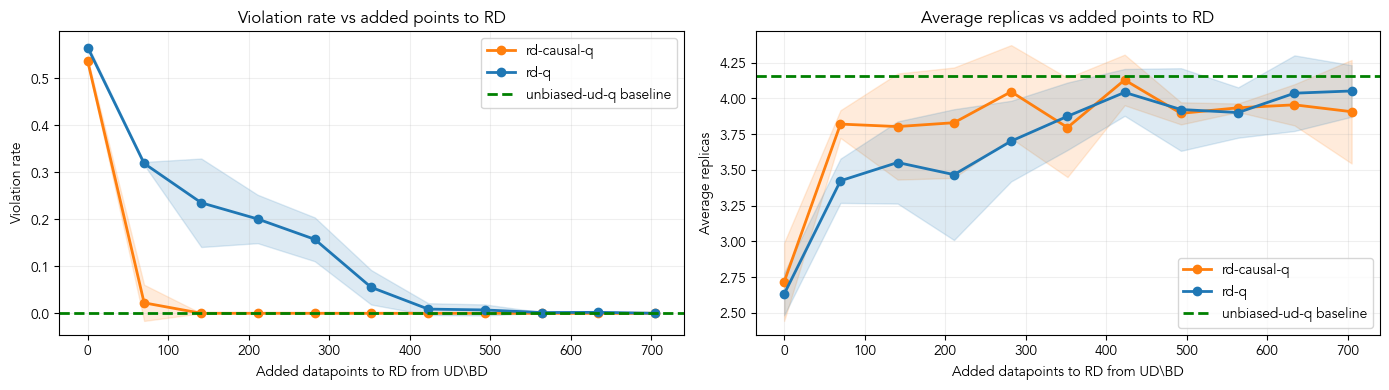

Point-addition seeds: 1000, repeats: 3
Unbiased baseline violation: 0.0000, avg replicas: 4.16


,added_points,agent,violation_rate_mean,violation_rate_std,avg_replicas_mean,avg_replicas_std,avg_reward_mean
0,0,rd-causal-q,0.535778,0.005347,2.717111,0.273391,-25.798008
2,70,rd-causal-q,0.022222,0.038490,3.820222,0.096796,52.794026
4,141,rd-causal-q,0.000000,0.000000,3.802889,0.370877,56.823961
6,211,rd-causal-q,0.000000,0.000000,3.829778,0.385959,56.624367
8,282,rd-causal-q,0.000000,0.000000,4.046444,0.325877,54.135747
10,352,rd-causal-q,0.000000,0.000000,3.796222,0.346642,56.933605
12,423,rd-causal-q,0.000000,0.000000,4.128667,0.177044,53.279620
14,493,rd-causal-q,0.000000,0.000000,3.895111,0.077349,55.927980
16,564,rd-causal-q,0.000000,0.000000,3.934222,0.029921,55.552274
18,634,rd-causal-q,0.000000,0.000000,3.954889,0.144158,55.205762


In [17]:
# ---- Progressive RD experiment ----
# Dynamically calculate ADD_PER_RUN to yield roughly 10 steps
ADD_PER_RUN = max(1, len(ud_minus_bd_df) // 10)
N_REPEATS = 3
RD_TRAIN_EPISODES = 2500
RD_EVAL_EPISODES = 300

# Point-addition order controls:
# - Use a single seed to lock the addition order family.
POINT_SEED = 1000

def make_dataset_info_from_df(df_local, path_label="in_memory"):
    return dataset_info_from_df(
        df_local,
        path_label=path_label,
        keep_columns=KEEP_COLUMNS,
        state_cols_override=STATE_SPACE_COLS,
        explicit_action_space=ACTION_SPACE,
    )

def train_unbiased_baseline(train_episodes):
    unbiased_env = make_env(ud_train_data, ud_train_artifacts, sla_latency_ms=SLA_LATENCY_MS)
    unbiased_agent_local = AgentClass(unbiased_env, **get_agent_kwargs())
    unbiased_agent_local.train(episodes=train_episodes)
    return unbiased_agent_local

# Unbiased baseline
unbiased_baseline_agent = train_unbiased_baseline(train_episodes=RD_TRAIN_EPISODES)
unbiased_eval_env = make_env(ud_test_data, ud_test_artifacts, sla_latency_ms=SLA_LATENCY_MS)
unbiased_metrics = evaluate_policy(unbiased_eval_env, unbiased_baseline_agent, episodes=RD_EVAL_EPISODES)

unbiased_violation_baseline = unbiased_metrics["violation_rate"]
unbiased_replicas_baseline = unbiased_metrics["avg_replicas"]

rd_rows = []
max_added = len(ud_minus_bd_df)
# Generate evenly spaced points to prevent clustering at the end
added_points_grid = sorted(list(set(int(x) for x in np.linspace(0, max_added, 11))))

for rep in range(N_REPEATS):
    rng = np.random.default_rng(POINT_SEED + rep)
    pool = ud_minus_bd_df.iloc[rng.permutation(len(ud_minus_bd_df))].reset_index(drop=True)

    for added_points in added_points_grid:
        added_df = pool.iloc[:added_points].copy()
        rd_df = pd.concat([base_bd_df, added_df], ignore_index=True)
        
        if len(rd_df) == 0:
            print(f"Skipping added_points={added_points} because RD dataset is empty.")
            continue
            
        rd_df = rd_df.sample(frac=1.0, random_state=rep).reset_index(drop=True)

        rd_info = make_dataset_info_from_df(
            rd_df,
            path_label=f"RD_seed{POINT_SEED}_rep{rep}_add{added_points}",
        )
        set_action_space(rd_info, GLOBAL_ACTIONS)
        rd_artifacts_local = build_dataset_artifacts(rd_info, n_bins=N_BINS)

        rd_train_env = make_env(rd_info, rd_artifacts_local, sla_latency_ms=SLA_LATENCY_MS)
        eval_env_local = make_env(ud_test_data, ud_test_artifacts, sla_latency_ms=SLA_LATENCY_MS)

        rd_q_agent = AgentClass(rd_train_env, **get_agent_kwargs())
        rd_q_agent.train(episodes=RD_TRAIN_EPISODES)

        rd_causal_agent = CausalAgentClass(
            rd_train_env,
            **get_agent_kwargs(is_causal=True)
        )
        rd_causal_agent.train(episodes=RD_TRAIN_EPISODES)

        metrics_rd_q = evaluate_policy(eval_env_local, rd_q_agent, episodes=RD_EVAL_EPISODES)
        metrics_rd_causal = evaluate_policy(eval_env_local, rd_causal_agent, episodes=RD_EVAL_EPISODES)

        rd_rows.extend([
            {
                "point_seed": int(POINT_SEED),
                "repeat": rep,
                "added_points": added_points,
                "rd_size": len(rd_df),
                "agent": "rd-q",
                "violation_rate": metrics_rd_q["violation_rate"],
                "avg_replicas": metrics_rd_q["avg_replicas"],
                "avg_reward": metrics_rd_q["avg_reward"],
            },
            {
                "point_seed": int(POINT_SEED),
                "repeat": rep,
                "added_points": added_points,
                "rd_size": len(rd_df),
                "agent": "rd-causal-q",
                "violation_rate": metrics_rd_causal["violation_rate"],
                "avg_replicas": metrics_rd_causal["avg_replicas"],
                "avg_reward": metrics_rd_causal["avg_reward"],
            },
        ])

rd_results_df = pd.DataFrame(rd_rows)

rd_summary = (
    rd_results_df
    .groupby(["added_points", "agent"], as_index=False)
    .agg(
        violation_rate_mean=("violation_rate", "mean"),
        violation_rate_std=("violation_rate", "std"),
        avg_replicas_mean=("avg_replicas", "mean"),
        avg_replicas_std=("avg_replicas", "std"),
        avg_reward_mean=("avg_reward", "mean"),
    )
    .sort_values(["agent", "added_points"])
)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
colors_rd = {"unbiased-ud-q baseline": "green", "rd-q": "#1f77b4", "rd-causal-q": "#ff7f0e"}
for agent_name, g in rd_summary.groupby("agent"):
    g = g.sort_values("added_points")
    x = g["added_points"].to_numpy(dtype=float)

    y_v = g["violation_rate_mean"].to_numpy(dtype=float)
    s_v = np.nan_to_num(g["violation_rate_std"].to_numpy(dtype=float), nan=0.0)
    axes[0].plot(x, y_v, marker="o", linewidth=2, label=agent_name, color=colors_rd.get(agent_name, None))
    axes[0].fill_between(x, y_v - s_v, y_v + s_v, alpha=0.15, color=colors_rd.get(agent_name, None))

    y_r = g["avg_replicas_mean"].to_numpy(dtype=float)
    s_r = np.nan_to_num(g["avg_replicas_std"].to_numpy(dtype=float), nan=0.0)
    axes[1].plot(x, y_r, marker="o", linewidth=2, label=agent_name, color=colors_rd.get(agent_name, None))
    axes[1].fill_between(x, y_r - s_r, y_r + s_r, alpha=0.15, color=colors_rd.get(agent_name, None))

axes[0].axhline(unbiased_violation_baseline, linestyle="--", linewidth=2, color="green", label="unbiased-ud-q baseline")
axes[1].axhline(unbiased_replicas_baseline, linestyle="--", linewidth=2, color="green", label="unbiased-ud-q baseline")

axes[0].set_title("Violation rate vs added points to RD")
axes[0].set_xlabel("Added datapoints to RD from UD\BD")
axes[0].set_ylabel("Violation rate")
axes[0].grid(alpha=0.2)
axes[0].legend()

axes[1].set_title("Average replicas vs added points to RD")
axes[1].set_xlabel("Added datapoints to RD from UD\BD")
axes[1].set_ylabel("Average replicas")
axes[1].grid(alpha=0.2)
axes[1].legend()

plt.tight_layout()
plt.show()

print(f"Point-addition seeds: {POINT_SEED}, repeats: {N_REPEATS}")
print(f"Unbiased baseline violation: {unbiased_violation_baseline:.4f}, avg replicas: {unbiased_replicas_baseline:.2f}")
display(rd_summary.head(15))

RD base size: 357 | Added points: 70 | RD total size: 427
Runs: 3


,sla_latency_ms,model,violation_rate_mean,violation_rate_min,violation_rate_max,avg_replicas_mean,avg_replicas_min,avg_replicas_max
0,120.0,rd-causal-q (+70),0.456444,0.328000,0.572000,4.461556,3.777333,4.842000
3,160.0,rd-causal-q (+70),0.201333,0.134667,0.245333,4.177778,3.724667,4.481333
6,200.0,rd-causal-q (+70),0.177556,0.069333,0.325333,4.157556,3.724667,4.446000
9,240.0,rd-causal-q (+70),0.187778,0.072667,0.276667,4.107556,3.642000,4.385333
12,280.0,rd-causal-q (+70),0.107556,0.049333,0.152000,3.998222,3.839333,4.188667
15,320.0,rd-causal-q (+70),0.073333,0.058000,0.100667,4.064444,3.940667,4.148667
18,360.0,rd-causal-q (+70),0.129778,0.025333,0.228000,3.832222,3.635333,4.018667
21,400.0,rd-causal-q (+70),0.130889,0.056000,0.188667,3.759556,3.565333,3.983333
24,440.0,rd-causal-q (+70),0.155556,0.061333,0.234000,3.517111,3.270000,3.798000
27,480.0,rd-causal-q (+70),0.076889,0.039333,0.096667,3.887333,3.615333,4.070667


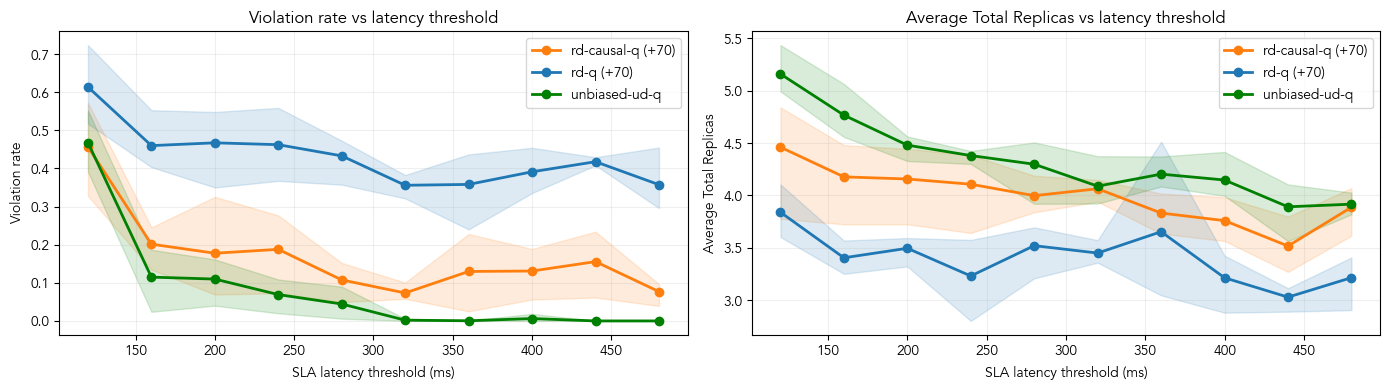

In [16]:
# ---- Experiment: RD vs latency threshold (3 models) ----
# Dynamically adjust the anchor to the size of your dataset (e.g. 20% of missing UD datapoints, or a specific ratio)
RD_ADDED_POINTS = max(1, int(len(ud_minus_bd_df) * 0.1)) # Dynamically adjusted anchor
RD60_POINT_SEED = 2026
THRESHOLD_VALUES = list(range(120, 501, 40))
THRESHOLD_TRAIN_EPISODES = 1500
THRESHOLD_EVAL_EPISODES = 300
THRESHOLD_N_REPEATS = 3

n_add = min(RD_ADDED_POINTS, len(ud_minus_bd_df))

results = []

for rep in range(THRESHOLD_N_REPEATS):
    rep_seed = RD60_POINT_SEED + rep
    rng_rd60 = np.random.default_rng(rep_seed)
    added_df_60 = ud_minus_bd_df.iloc[rng_rd60.permutation(len(ud_minus_bd_df))[:n_add]].copy()

    rd60_df = pd.concat([base_bd_df, added_df_60], ignore_index=True)
    if len(rd60_df) > 0:
        rd60_df = rd60_df.sample(frac=1.0, random_state=rep_seed).reset_index(drop=True)
    else:
        print(f"Warning: RD(+{n_add}) is empty on repeat {rep}.")
        
    rd60_info = make_dataset_info_from_df(rd60_df, path_label=f"RD_plus_{n_add}_points_rep_{rep}")
    set_action_space(rd60_info, GLOBAL_ACTIONS)
    rd60_artifacts = build_dataset_artifacts(rd60_info, n_bins=N_BINS)

    for sla in THRESHOLD_VALUES:
        # Unbiased baseline: train on UD-train, evaluate on UD-test
        unbiased_train_env = make_env(ud_train_data, ud_train_artifacts, sla_latency_ms=float(sla))
        unbiased_agent = AgentClass(unbiased_train_env, **get_agent_kwargs())
        unbiased_agent.train(episodes=THRESHOLD_TRAIN_EPISODES)

        # RD-Q: train on RD(+60), evaluate on UD-test
        rd_q_train_env = make_env(rd60_info, rd60_artifacts, sla_latency_ms=float(sla))
        rd_q_agent = AgentClass(rd_q_train_env, **get_agent_kwargs())
        rd_q_agent.train(episodes=THRESHOLD_TRAIN_EPISODES)

        # RD-Causal-Q: train on RD(+60), evaluate on UD-test
        rd_causal_train_env = make_env(rd60_info, rd60_artifacts, sla_latency_ms=float(sla))
        rd_causal_agent = CausalAgentClass(
            rd_causal_train_env,
            **get_agent_kwargs(is_causal=True)
        )
        rd_causal_agent.train(episodes=THRESHOLD_TRAIN_EPISODES)

        eval_env_local = make_env(ud_test_data, ud_test_artifacts, sla_latency_ms=float(sla))

        m_unbiased = evaluate_policy(eval_env_local, unbiased_agent, episodes=THRESHOLD_EVAL_EPISODES)
        m_rd_q = evaluate_policy(eval_env_local, rd_q_agent, episodes=THRESHOLD_EVAL_EPISODES)
        m_rd_causal = evaluate_policy(eval_env_local, rd_causal_agent, episodes=THRESHOLD_EVAL_EPISODES)

        results.extend([
            {"repeat": rep, "model": "unbiased-ud-q", "sla_latency_ms": float(sla), **m_unbiased},
            {"repeat": rep, "model": f"rd-q (+{n_add})", "sla_latency_ms": float(sla), **m_rd_q},
            {"repeat": rep, "model": f"rd-causal-q (+{n_add})", "sla_latency_ms": float(sla), **m_rd_causal},
        ])

rd60_vs_sla_df = pd.DataFrame(results)

# Aggregate across repeats
rd60_summary = (
    rd60_vs_sla_df
    .groupby(["sla_latency_ms", "model"], as_index=False)
    .agg(
        violation_rate_mean=("violation_rate", "mean"),
        violation_rate_min=("violation_rate", "min"),
        violation_rate_max=("violation_rate", "max"),
        avg_replicas_mean=("avg_replicas", "mean"),
        avg_replicas_min=("avg_replicas", "min"),
        avg_replicas_max=("avg_replicas", "max"),
    )
    .sort_values(["model", "sla_latency_ms"])
)

print(f"RD base size: {len(base_bd_df)} | Added points: {n_add} | RD total size: {len(rd60_df)}")
print(f"Runs: {THRESHOLD_N_REPEATS}")
display(rd60_summary.head(12))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
colors_sla = {"unbiased-ud-q": "green", f"rd-q (+{n_add})": "#1f77b4", f"rd-causal-q (+{n_add})": "#ff7f0e"}

for model_name, g in rd60_summary.groupby("model"):
    g = g.sort_values("sla_latency_ms")
    x = g["sla_latency_ms"].to_numpy(dtype=float)
    
    y_v = g["violation_rate_mean"].to_numpy(dtype=float)
    y_v_min = g["violation_rate_min"].to_numpy(dtype=float)
    y_v_max = g["violation_rate_max"].to_numpy(dtype=float)
    axes[0].plot(x, y_v, marker="o", linewidth=2, label=model_name, color=colors_sla.get(model_name, None))
    axes[0].fill_between(x, y_v_min, y_v_max, alpha=0.15, color=colors_sla.get(model_name, None))
    
    y_r = g["avg_replicas_mean"].to_numpy(dtype=float)
    y_r_min = g["avg_replicas_min"].to_numpy(dtype=float)
    y_r_max = g["avg_replicas_max"].to_numpy(dtype=float)
    axes[1].plot(x, y_r, marker="o", linewidth=2, label=model_name, color=colors_sla.get(model_name, None))
    axes[1].fill_between(x, y_r_min, y_r_max, alpha=0.15, color=colors_sla.get(model_name, None))

axes[0].set_title("Violation rate vs latency threshold")
axes[0].set_xlabel("SLA latency threshold (ms)")
axes[0].set_ylabel("Violation rate")
axes[0].grid(alpha=0.2)
axes[0].legend()

axes[1].set_title("Average Total Replicas vs latency threshold")
axes[1].set_xlabel("SLA latency threshold (ms)")
axes[1].set_ylabel("Average Total Replicas")
axes[1].grid(alpha=0.2)
axes[1].legend()

plt.tight_layout()
plt.show()